<a href="https://colab.research.google.com/github/mochamadx5/MachineLearning_11_MochamadReza/blob/main/JS05/JS05_TugasLab01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
# 1. Memuat Dataset
df = pd.read_csv('voice.csv')

In [3]:
# Memisahkan fitur (X) dan target (y)
X = df.drop('label', axis=1)
y = df['label']

In [4]:
# Encode label target ('male'/'female' menjadi 1/0)
le = LabelEncoder()
y = le.fit_transform(y)

In [5]:
# Standardisasi fitur (Sangat krusial untuk kNN yang berbasis metrik jarak)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

In [6]:
# ==========================================
# 2. Eksperimen Fitur Optimal
# ==========================================
# Menggunakan Random Forest untuk mendapatkan bobot kepentingan fitur (Feature Importances)
rf = RandomForestClassifier(random_state=42)
rf.fit(X_scaled, y)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
ranked_features = X.columns[indices]

best_score = 0
best_features = []

In [7]:
# Menguji subset fitur (dari yang paling penting) untuk mencari akurasi kNN tertinggi
for i in range(1, len(ranked_features) + 1):
    features_subset = ranked_features[:i]
    X_sub = X_scaled[features_subset]

    knn = KNeighborsClassifier(n_neighbors=5)
    score = cross_val_score(knn, X_sub, y, cv=5).mean()

    if score > best_score:
        best_score = score
        best_features = features_subset.tolist()

print(f"Fitur optimal terpilih ({len(best_features)} fitur): {best_features}")

Fitur optimal terpilih (6 fitur): ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'sfm']


In [8]:
# ==========================================
# 3 & 4. Mencari Nilai k Terbaik & Visualisasi
# ==========================================
# Gunakan hanya fitur-fitur terbaik yang didapat dari tahap sebelumnya
X_opt = X_scaled[best_features]
X_train, X_test, y_train, y_test = train_test_split(X_opt, y, test_size=0.2, random_state=42)

k_range = range(1, 31)
k_scores = []

In [9]:
# Menguji nilai k dari 1 hingga 30
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    # Validasi silang (10-Fold CV) pada data latih
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    k_scores.append(scores.mean())

optimal_k = k_range[np.argmax(k_scores)]
best_k_score = max(k_scores)
print(f"Nilai k terbaik: {optimal_k} dengan akurasi CV: {best_k_score:.4f}")

Nilai k terbaik: 7 dengan akurasi CV: 0.9834


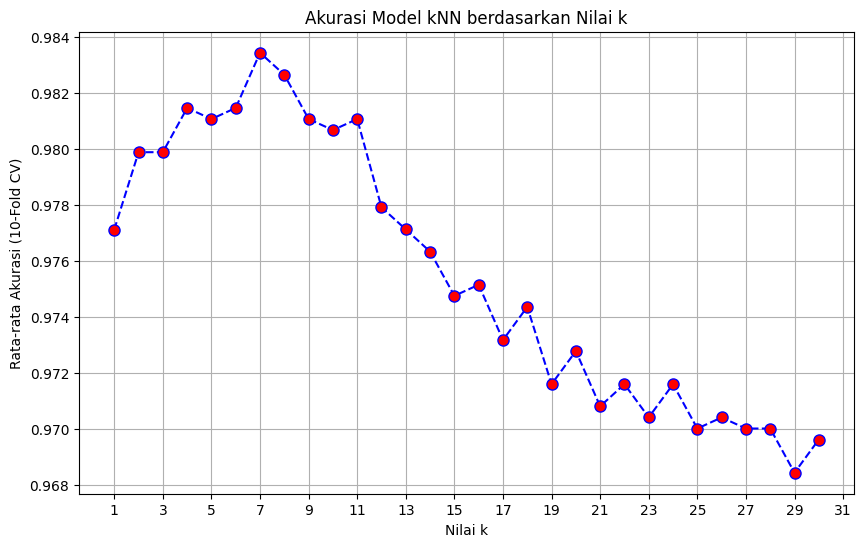

In [10]:
# Visualisasi Grafik
plt.figure(figsize=(10, 6))
plt.plot(k_range, k_scores, marker='o', linestyle='dashed', color='blue', markerfacecolor='red', markersize=8)
plt.title('Akurasi Model kNN berdasarkan Nilai k')
plt.xlabel('Nilai k')
plt.ylabel('Rata-rata Akurasi (10-Fold CV)')
plt.xticks(np.arange(1, 32, 2))
plt.grid(True)
plt.show()